# Customer Churn – Logistic Regression
Target: `churned` (1 = churned).

**Setup:** the file used here is the 80% training split, already preprocessed (RobustScaler + missing-indicator flags). So we train on **all** of it, use **cross-validation** for tuning and honest performance estimates, and keep the separate 20% test file untouched until the very end.

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay,
                             average_precision_score, precision_recall_curve)

RANDOM_STATE = 42
TRAIN_FILE = "model_ready_train.csv"
TEST_FILE  = "model_ready_test.csv"   # your preprocessed 20% test file (change name/path if different)

## 1. Load training data

In [3]:
train = pd.read_csv(TRAIN_FILE)
X_train = train.drop(columns="churned")
y_train = train["churned"]

print(X_train.shape, "| missing values:", train.isna().sum().sum())
print(y_train.value_counts(normalize=True).rename("share"))

(40000, 40) | missing values: 0
churned
0    0.711
1    0.289
Name: share, dtype: float64


## 2. Baseline (5-fold cross-validated)
Out-of-fold predictions: every row is scored by a model that never saw it.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

base = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
p_base = cross_val_predict(base, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
print(f"Baseline CV ROC-AUC: {roc_auc_score(y_train, p_base):.4f}")
print(f"Baseline CV PR-AUC : {average_precision_score(y_train, p_base):.4f}")
print(classification_report(y_train, (p_base >= 0.5).astype(int), digits=3))

Baseline CV ROC-AUC: 0.7957
Baseline CV PR-AUC : 0.6505
              precision    recall  f1-score   support

           0      0.803     0.922     0.859     28440
           1      0.699     0.445     0.544     11560

    accuracy                          0.784     40000
   macro avg      0.751     0.684     0.701     40000
weighted avg      0.773     0.784     0.768     40000



## 3. Tune regularisation strength `C`
`class_weight='balanced'` makes the model pay more attention to churners (the minority class). `GridSearchCV` refits the best model on **all** training rows.

In [12]:
grid = GridSearchCV(
    LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    param_grid={"C": [0.001, 0.01, 0.1, 1, 10, 100]},
    scoring="roc_auc", cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)

print("Best params :", grid.best_params_)
print(f"Best CV AUC : {grid.best_score_:.4f}")
#model = grid.best_estimator_
model_v1 = grid.best_estimator_ 

Best params : {'C': 0.1}
Best CV AUC : 0.7957


In [ ]:
## 3a. Optimized Version

In [13]:
from sklearn.model_selection import cross_validate
import time

# Two different CV splits: one to PICK the parameters, one for a fair before/after comparison
cv_tune = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_eval = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)

scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision",
           "precision": "precision", "recall": "recall", "f1": "f1"}

base_model = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)   # default settings (C=1, L2, no class weight)

def cv_scores(est, name):
    res = cross_validate(est, X_train, y_train, cv=cv_eval, scoring=scoring, n_jobs=-1)
    return pd.Series({m: res[f"test_{m}"].mean() for m in scoring}, name=name)

base_scores = cv_scores(base_model, "Base model")
base_scores

roc_auc      0.795589
pr_auc       0.650544
precision    0.698655
recall       0.444723
f1           0.543478
Name: Base model, dtype: float64

In [14]:
grid_params = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100],
    "penalty": ["l1", "l2"],
    "class_weight": [None, "balanced"],
}

grid = GridSearchCV(
    LogisticRegression(solver="liblinear", max_iter=2000, random_state=RANDOM_STATE),  # liblinear supports both l1 and l2
    param_grid=grid_params,
    scoring={"f1": "f1", "roc_auc": "roc_auc", "recall": "recall"},
    refit="f1",               # the best parameters = highest F1
    cv=cv_tune, n_jobs=-1)

t0 = time.time()
grid.fit(X_train, y_train)
grid_time = time.time() - t0

print(f"Grid Search finished in {grid_time:.1f}s ({len(grid.cv_results_['params'])} combinations x 5 folds)")
print("Best parameters:", grid.best_params_)
print(f"Best CV F1: {grid.best_score_:.4f}")

# Top 5 combinations
(pd.DataFrame(grid.cv_results_)
   .sort_values("rank_test_f1")
   [["param_C", "param_penalty", "param_class_weight", "mean_test_f1", "mean_test_roc_auc"]]
   .head(5))

Grid Search finished in 6.8s (24 combinations x 5 folds)
Best parameters: {'C': 1, 'class_weight': 'balanced', 'penalty': 'l1'}
Best CV F1: 0.6042


,param_C,param_penalty,param_class_weight,mean_test_f1,mean_test_roc_auc
14,1,l1,balanced,0.604240,0.795645
11,0.1,l2,balanced,0.604174,0.795653
10,0.1,l1,balanced,0.604082,0.795559
15,1,l2,balanced,0.604019,0.795640
19,10,l2,balanced,0.603963,0.795612


In [15]:
grid_scores = cv_scores(grid.best_estimator_, "Tuned (Grid Search)")

comparison = pd.concat([base_scores, grid_scores], axis=1).T
comparison.loc["Improvement (Δ)"] = comparison.loc["Tuned (Grid Search)"] - comparison.loc["Base model"]
comparison.round(4)

,roc_auc,pr_auc,precision,recall,f1
Base model,0.7956,0.6505,0.6987,0.4447,0.5435
Tuned (Grid Search),0.7955,0.6442,0.5155,0.7283,0.6037
Improvement (Δ),-0.0001,-0.0064,-0.1832,0.2836,0.0602


In [16]:
doc = pd.DataFrame({
    "Parameters investigated": [
        "C: [0.001, 0.01, 0.1, 1, 10, 100]\npenalty: [l1, l2]\nclass_weight: [None, balanced]"],
    "Combinations x folds": [f"{len(grid.cv_results_['params'])} x 5 = {len(grid.cv_results_['params']) * 5} fits"],
    "Optimal values": [str(grid.best_params_)],
    "Run time (s)": [round(grid_time, 1)],
}).T
doc.columns = ["Grid Search"]
display(doc)

perf = pd.DataFrame({
    "Base model": base_scores,
    "Tuned model": grid_scores,
})
perf["Improvement"] = perf["Tuned model"] - perf["Base model"]
perf.round(4)

,Grid Search
Parameters investigated,"C: [0.001, 0.01, 0.1, 1, 10, 100]\npenalty: [l..."
Combinations x folds,24 x 5 = 120 fits
Optimal values,"{'C': 1, 'class_weight': 'balanced', 'penalty'..."
Run time (s),6.8


,Base model,Tuned model,Improvement
roc_auc,0.7956,0.7955,-0.0001
pr_auc,0.6505,0.6442,-0.0064
precision,0.6987,0.5155,-0.1832
recall,0.4447,0.7283,0.2836
f1,0.5435,0.6037,0.0602


In [17]:
model = grid.best_estimator_
print(model)

LogisticRegression(C=1, class_weight='balanced', max_iter=2000, penalty='l1',
                   random_state=42, solver='liblinear')


## 4. Choose the decision threshold
The default 0.5 is rarely best for churn. We choose it from out-of-fold predictions on the training data (so the test file stays untouched).

Threshold maximising F1 (churn class): 0.549


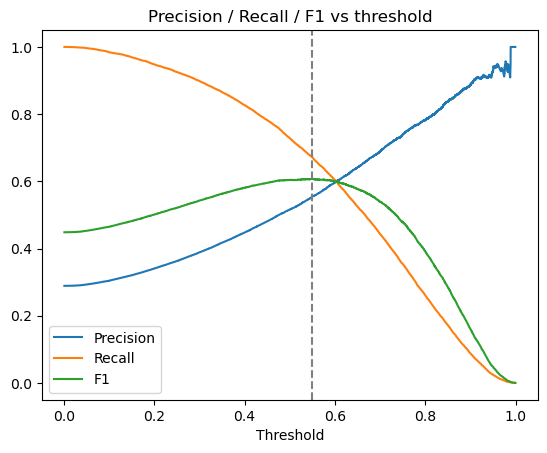

In [6]:
oof = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
best_thr = thr[np.argmax(f1)]
print(f"Threshold maximising F1 (churn class): {best_thr:.3f}")

plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.plot(thr, f1, label="F1")
plt.axvline(best_thr, ls="--", c="grey")
plt.xlabel("Threshold"); plt.legend(); plt.title("Precision / Recall / F1 vs threshold")
plt.show()

## 5. Cross-validated performance (training data)
This is your estimate of how the model should perform on unseen data.

CV ROC-AUC: 0.7956
CV PR-AUC : 0.6443

              precision    recall  f1-score   support

           0      0.854     0.780     0.815     28440
           1      0.554     0.673     0.608     11560

    accuracy                          0.749     40000
   macro avg      0.704     0.726     0.711     40000
weighted avg      0.767     0.749     0.755     40000



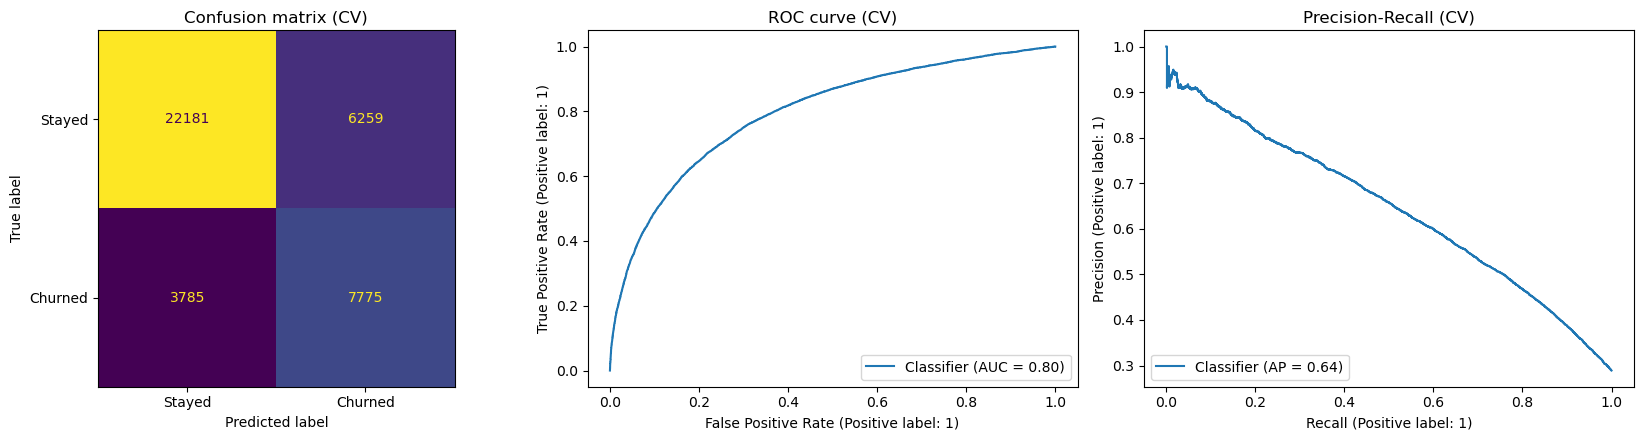

In [7]:
pred_oof = (oof >= best_thr).astype(int)
print(f"CV ROC-AUC: {roc_auc_score(y_train, oof):.4f}")
print(f"CV PR-AUC : {average_precision_score(y_train, oof):.4f}\n")
print(classification_report(y_train, pred_oof, digits=3))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_train, pred_oof),
                       display_labels=["Stayed", "Churned"]).plot(ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix (CV)")
RocCurveDisplay.from_predictions(y_train, oof, ax=ax[1]); ax[1].set_title("ROC curve (CV)")
PrecisionRecallDisplay.from_predictions(y_train, oof, ax=ax[2]); ax[2].set_title("Precision-Recall (CV)")
plt.tight_layout(); plt.show()

## 6. What drives churn? (coefficients & odds ratios)
All features share a comparable RobustScaler scale, so coefficient sizes can be compared directly.

- **Positive coef / odds ratio > 1** → higher value raises churn risk
- **Negative coef / odds ratio < 1** → higher value lowers churn risk

Odds ratio = change in churn odds for a **1 IQR increase** of the original feature (RobustScaler divides by the IQR).

,feature,coef,importance,importance_pct,effect,odds_ratio
0,login_page_activity,1.169094,1.169094,16.159064,raises churn,3.219074
1,lifetime_value,0.952858,0.952858,13.170284,raises churn,2.593110
2,login_frequency,-0.828344,0.828344,11.449260,lowers churn,0.436772
3,cart_abandonment_rate,0.742927,0.742927,10.268637,raises churn,2.102078
4,pages_per_session,-0.712659,0.712659,9.850288,lowers churn,0.490338
5,customer_service_calls,0.699707,0.699707,9.671260,raises churn,2.013162
6,age,-0.412713,0.412713,5.704472,lowers churn,0.661852
7,days_since_last_purchase,0.398853,0.398853,5.512901,raises churn,1.490115
8,discount_usage_rate,-0.309200,0.309200,4.273730,lowers churn,0.734034
9,email_open_rate,-0.299044,0.299044,4.133347,lowers churn,0.741527


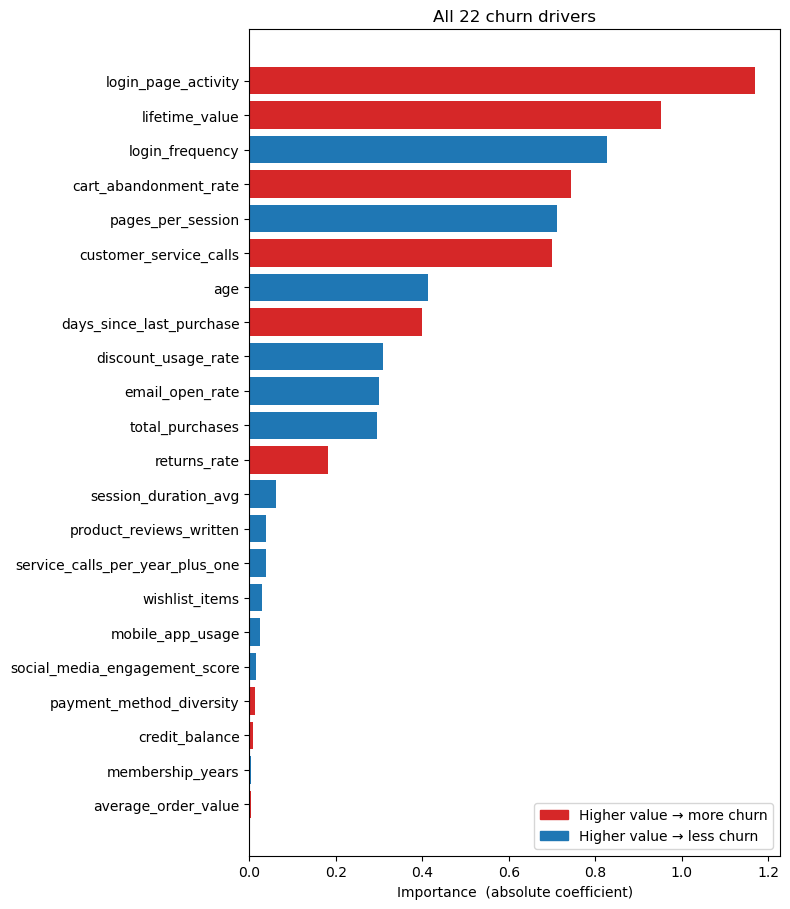

In [9]:
# Keep all real feature columns (drop the missing-indicator flags; the target is already excluded)
coef = pd.DataFrame({
    "feature": X_train.columns.str.replace("numeric__", "", regex=False),
    "coef": model.coef_[0],
})
coef = coef[~coef["feature"].str.startswith("missingindicator")].copy()

# Importance = size of the weight, regardless of direction
coef["importance"] = coef["coef"].abs()
coef["importance_pct"] = 100 * coef["importance"] / coef["importance"].sum()
coef["effect"] = np.where(coef["coef"] > 0, "raises churn", "lowers churn")
coef["odds_ratio"] = np.exp(coef["coef"])
coef = coef.sort_values("importance", ascending=False).reset_index(drop=True)

pd.set_option("display.max_rows", None)   # show every row, not just the first few
display(coef)

# Chart: all features. Bar length = importance, colour = direction
from matplotlib.patches import Patch
plot_df = coef.iloc[::-1]
colors = np.where(plot_df["coef"] > 0, "tab:red", "tab:blue")

plt.figure(figsize=(8, 0.35 * len(plot_df) + 1.5))   # chart height grows with the number of features
plt.barh(plot_df["feature"], plot_df["importance"], color=colors)
plt.xlabel("Importance  (absolute coefficient)")
plt.title(f"All {len(plot_df)} churn drivers")
plt.legend(handles=[Patch(color="tab:red", label="Higher value → more churn"),
                    Patch(color="tab:blue", label="Higher value → less churn")],
           loc="lower right")
plt.tight_layout(); plt.show()

## 7. Final evaluation on the held-out 20% test file
Run this **once**, after you're happy with the model. The test file must be preprocessed with the scaler/imputer **fitted on the training data** (never re-fitted on test).

Test ROC-AUC: 0.7984
Test PR-AUC : 0.6406

              precision    recall  f1-score   support

           0      0.854     0.778     0.814      7110
           1      0.552     0.673     0.606      2890

    accuracy                          0.748     10000
   macro avg      0.703     0.725     0.710     10000
weighted avg      0.767     0.748     0.754     10000



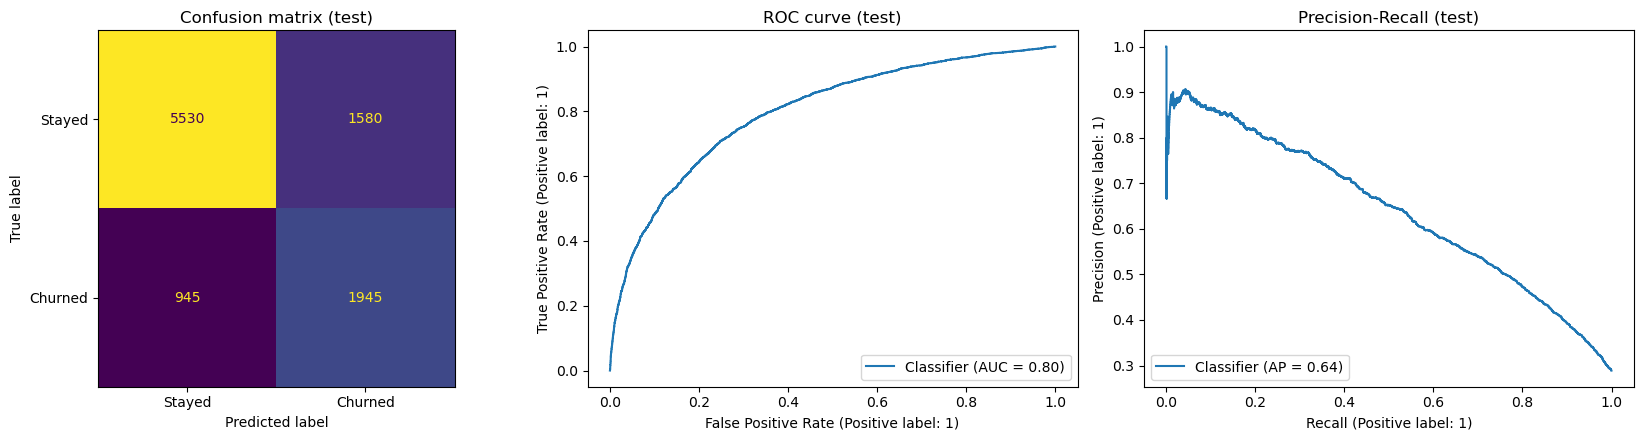

In [19]:
test = pd.read_csv(TEST_FILE)
X_test = test[X_train.columns]          # same columns, same order
y_test = test["churned"]

p_test = model.predict_proba(X_test)[:, 1]
pred_test = (p_test >= best_thr).astype(int)

print(f"Test ROC-AUC: {roc_auc_score(y_test, p_test):.4f}")
print(f"Test PR-AUC : {average_precision_score(y_test, p_test):.4f}\n")
print(classification_report(y_test, pred_test, digits=3))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test),
                       display_labels=["Stayed", "Churned"]).plot(ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix (test)")
RocCurveDisplay.from_predictions(y_test, p_test, ax=ax[1]); ax[1].set_title("ROC curve (test)")
PrecisionRecallDisplay.from_predictions(y_test, p_test, ax=ax[2]); ax[2].set_title("Precision-Recall (test)")
plt.tight_layout(); plt.show()

In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def test_row(name, p, thr):
    pred = (p >= thr).astype(int)
    return pd.Series({"accuracy": accuracy_score(y_test, pred), "roc_auc": roc_auc_score(y_test, p),
                      "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
                      "f1": f1_score(y_test, pred)}, name=name)

base_final = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE).fit(X_train, y_train)

rows = [
    test_row("Base model (threshold 0.5)", base_final.predict_proba(X_test)[:, 1], 0.5),
    test_row("Tuned model (threshold 0.5)", model.predict_proba(X_test)[:, 1], 0.5),
    test_row(f"Tuned model + threshold {best_thr:.3f}", p_test, best_thr),
]
pd.DataFrame(rows).round(4)

,accuracy,roc_auc,precision,recall,f1
Base model (threshold 0.5),0.7830,0.7987,0.6907,0.4512,0.5458
Tuned model (threshold 0.5),0.7257,0.7984,0.5179,0.7349,0.6076
Tuned model + threshold 0.549,0.7475,0.7986,0.5517,0.6734,0.6065


## 8. Save the model
The threshold is saved with the model so predictions stay consistent.

In [ ]:
joblib.dump({"model": model, "threshold": float(best_thr), "features": list(X_train.columns)},
            "churn_logreg.joblib")
print("Saved churn_logreg.joblib")

## 9. Predicting on new customers
New raw data must go through the **same fitted preprocessing pipeline** used for the training file.

```python
art = joblib.load("churn_logreg.joblib")
X_new = preprocessor.transform(raw_new_df)        # your saved, fitted preprocessing pipeline
X_new = pd.DataFrame(X_new, columns=art["features"])
churn_prob = art["model"].predict_proba(X_new)[:, 1]
churn_flag = (churn_prob >= art["threshold"]).astype(int)
```